In [1]:
%pip install -q torch torchvision diffusers transformers accelerate safetensors rembg onnxruntime opencv-python-headless pandas matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\admin\\gpu_env\\Lib\\site-packages\\cv2\\cv2.pyd'
Check the permissions.



In [2]:

from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

PRODUCT_ID = "P001"
PRODUCT_NAME = "Teal Geometric Polo"
PRODUCT_CATEGORY = "polo shirt"

DATA_DIR = Path("tshirt_dataset/selected/set_1")
FRONT_PATH = DATA_DIR / "front.jpg"
BACK_PATH = DATA_DIR / "back.jpg"

# Set this to the uploaded image if you want to use it as the front input.
# FRONT_PATH = Path("/mnt/data/front.png")

OUTPUT_DIR = Path("generated_designs") / PRODUCT_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 768
SEED = 42
NUM_INFERENCE_STEPS = 20
GUIDANCE_SCALE = 7.0

DESIGN_PROMPT = (
    "a premium teal polo shirt with elegant copper geometric line patterns, "
    "refined symmetrical angular details, realistic knitted fabric, "
    "professional apparel product photography, preserve the original garment shape"
)

NEGATIVE_PROMPT = (
    "watermark, logo text, extra buttons, malformed collar, distorted sleeves, "
    "deformed garment, blurry fabric, extra limbs, low quality"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.float16
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = "mps"
    DTYPE = torch.float32
else:
    DEVICE = "cpu"
    DTYPE = torch.float32

for path in [FRONT_PATH, BACK_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing input image: {path.resolve()}")

print("Product:", PRODUCT_NAME)
print("Device:", DEVICE)
print("Output folder:", OUTPUT_DIR.resolve())


Product: Teal Geometric Polo
Device: cuda
Output folder: C:\Users\admin\Documents\ann_ajay_project\generated_designs\P001


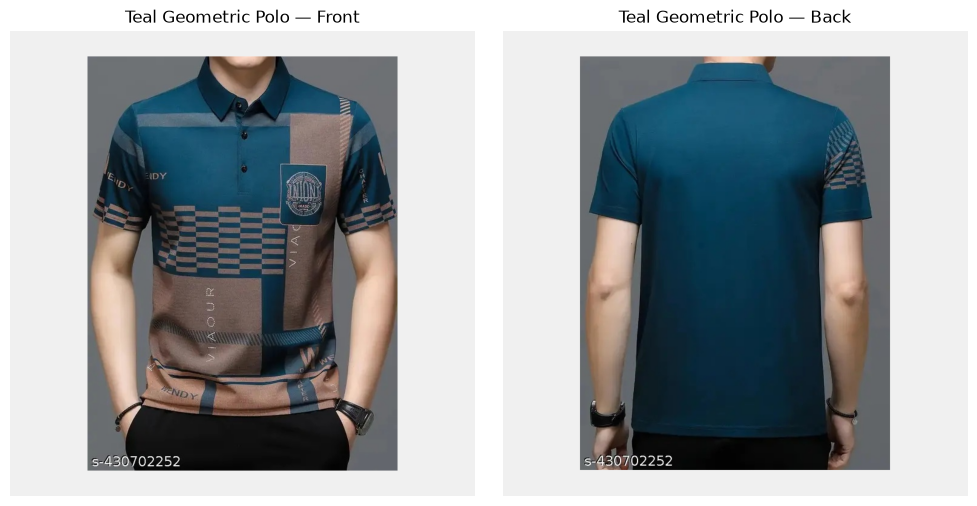

In [3]:

from PIL import Image, ImageOps

def preprocess_image(path, size=IMAGE_SIZE):
    image = Image.open(path).convert("RGB")
    image = ImageOps.exif_transpose(image)

    image.thumbnail((size, size), Image.Resampling.LANCZOS)

    canvas = Image.new("RGB", (size, size), (240, 240, 240))
    x = (size - image.width) // 2
    y = (size - image.height) // 2
    canvas.paste(image, (x, y))

    return canvas

source_images = {
    "front": preprocess_image(FRONT_PATH),
    "back": preprocess_image(BACK_PATH)
}

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (view, image) in zip(axes, source_images.items()):
    ax.imshow(image)
    ax.set_title(f"{PRODUCT_NAME} — {view.title()}")
    ax.axis("off")

plt.tight_layout()
plt.show()


Segmentation completed.


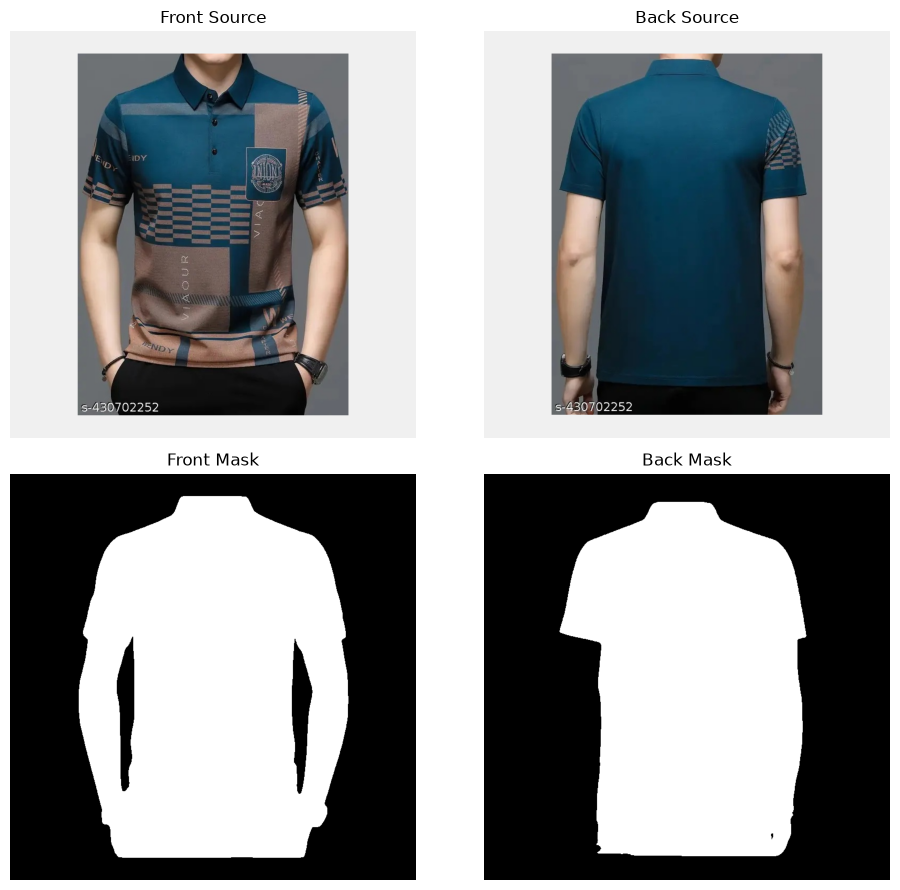

In [5]:

from rembg import new_session, remove
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Load the segmentation model once
segmentation_session = new_session("u2net")

masks = {}

for view, image in source_images.items():

    # remove() may return a PIL Image or bytes depending on the input.
    result = remove(
        image,
        session=segmentation_session,
        only_mask=True
    )

    # Handle both supported return types
    if isinstance(result, Image.Image):
        mask = result.convert("L")
    else:
        from io import BytesIO
        mask = Image.open(BytesIO(result)).convert("L")

    # Ensure consistent dimensions
    mask = mask.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.LANCZOS
    )

    # Convert to a clean binary mask
    mask = mask.point(lambda pixel: 255 if pixel >= 128 else 0)

    masks[view] = mask

print("Segmentation completed.")

# Display the source images and masks
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for col, view in enumerate(["front", "back"]):
    axes[0, col].imshow(source_images[view])
    axes[0, col].set_title(f"{view.title()} Source")
    axes[0, col].axis("off")

    axes[1, col].imshow(masks[view], cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title(f"{view.title()} Mask")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()


In [6]:

from torchvision import models, transforms

weights = models.ResNet18_Weights.DEFAULT
cnn = models.resnet18(weights=weights)
cnn.fc = torch.nn.Identity()
cnn = cnn.to(DEVICE).eval()

cnn_preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

cnn_features = {}

with torch.inference_mode():
    for view, image in source_images.items():
        tensor = cnn_preprocess(image).unsqueeze(0).to(DEVICE)
        features = cnn(tensor).squeeze(0)
        cnn_features[view] = features.cpu().numpy()

print("ResNet18 weights:", weights)
for view, features in cnn_features.items():
    print(view, "feature shape:", features.shape)


ResNet18 weights: ResNet18_Weights.IMAGENET1K_V1
front feature shape: (512,)
back feature shape: (512,)


In [7]:

import cv2

color_features = {}

for view, image in source_images.items():
    rgb = np.asarray(image)

    histograms = []
    for channel in range(3):
        hist = cv2.calcHist(
            [rgb], [channel], None, [4], [0, 256]
        ).flatten()

        hist = hist / (hist.sum() + 1e-8)
        histograms.extend(hist)

    color_features[view] = np.asarray(histograms, dtype=np.float32)

    print(view, "colour feature shape:", color_features[view].shape)


front colour feature shape: (12,)
back colour feature shape: (12,)


In [8]:

def make_combined_features(view):
    cnn_vector = cnn_features[view].astype(np.float32)
    color_vector = color_features[view].astype(np.float32)

    # Normalize each feature group so the 512-D CNN vector
    # does not overwhelm the 12-D colour descriptor.
    cnn_vector /= np.linalg.norm(cnn_vector) + 1e-8
    color_vector /= np.linalg.norm(color_vector) + 1e-8

    return np.concatenate([cnn_vector, color_vector])

front_vector = make_combined_features("front")
back_vector = make_combined_features("back")

# Convert each continuous descriptor into a bipolar pattern {-1, +1}.
front_pattern = np.where(front_vector >= 0, 1.0, -1.0)
back_pattern = np.where(back_vector >= 0, 1.0, -1.0)

# Hebbian BAM learning: associate front with back.
bam_weights = np.outer(front_pattern, back_pattern)

# Recall the back pattern from the front pattern.
back_recalled = np.where(front_pattern @ bam_weights >= 0, 1.0, -1.0)

bam_recall_accuracy = np.mean(back_recalled == back_pattern)

# A continuous feature similarity is also useful for inspection.
front_back_cosine = float(
    np.dot(front_vector, back_vector) /
    ((np.linalg.norm(front_vector) * np.linalg.norm(back_vector)) + 1e-8)
)

print("BAM weight matrix:", bam_weights.shape)
print("BAM recall agreement:", round(float(bam_recall_accuracy), 4))
print("Front/back cosine similarity:", round(front_back_cosine, 4))


BAM weight matrix: (524, 524)
BAM recall agreement: 1.0
Front/back cosine similarity: 0.8927


In [9]:

design_spec = {
    "product_id": PRODUCT_ID,
    "product_name": PRODUCT_NAME,
    "category": PRODUCT_CATEGORY,
    "design_direction": DESIGN_PROMPT,
    "bam_recall_agreement": float(bam_recall_accuracy),
    "front_back_similarity": front_back_cosine
}

if bam_recall_accuracy >= 0.90:
    consistency_instruction = (
        "Use the same design language, colour palette, and geometric motif "
        "across the front and back views of the same garment."
    )
else:
    consistency_instruction = (
        "Preserve the original garment structure and use the same specified "
        "design direction for both views."
    )

shared_prompt = (
    f"{PRODUCT_CATEGORY}, {PRODUCT_NAME}. "
    f"{design_spec['design_direction']}. "
    f"{consistency_instruction}"
)

design_spec["shared_prompt"] = shared_prompt

print("Shared design specification:")
for key, value in design_spec.items():
    print(f"{key}: {value}")


Shared design specification:
product_id: P001
product_name: Teal Geometric Polo
category: polo shirt
design_direction: a premium teal polo shirt with elegant copper geometric line patterns, refined symmetrical angular details, realistic knitted fabric, professional apparel product photography, preserve the original garment shape
bam_recall_agreement: 1.0
front_back_similarity: 0.8926637768745422
shared_prompt: polo shirt, Teal Geometric Polo. a premium teal polo shirt with elegant copper geometric line patterns, refined symmetrical angular details, realistic knitted fabric, professional apparel product photography, preserve the original garment shape. Use the same design language, colour palette, and geometric motif across the front and back views of the same garment.


In [10]:

from diffusers import StableDiffusionXLInpaintPipeline

MODEL_ID = "diffusers/stable-diffusion-xl-1.0-inpainting-0.1"

inpaint_pipe = StableDiffusionXLInpaintPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
    use_safetensors=True
)

if DEVICE == "cuda":
    inpaint_pipe.enable_model_cpu_offload()
else:
    inpaint_pipe = inpaint_pipe.to(DEVICE)

inpaint_pipe.enable_attention_slicing()

if hasattr(inpaint_pipe, "enable_vae_slicing"):
    inpaint_pipe.enable_vae_slicing()

print("SDXL loaded:", MODEL_ID)
print("Generation device:", DEVICE)


C:\Users\admin\gpu_env\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...:  29%|██▊       | 2/7 [00:00<00:00, 18.20it/s]The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.

Loading pipeline components...: 100%|██████████| 7/7 [00:07<00:00,  1.08s/it]


SDXL loaded: diffusers/stable-diffusion-xl-1.0-inpainting-0.1
Generation device: cuda


In [11]:

generated_images = {}
generation_records = []

for view in ["front", "back"]:
    generator = torch.Generator(device=DEVICE).manual_seed(SEED)

    result = inpaint_pipe(
        prompt=shared_prompt,
        negative_prompt=NEGATIVE_PROMPT,
        image=source_images[view],
        mask_image=masks[view],
        width=IMAGE_SIZE,
        height=IMAGE_SIZE,
        num_inference_steps=NUM_INFERENCE_STEPS,
        guidance_scale=GUIDANCE_SCALE,
        strength=0.65,
        generator=generator
    )

    generated = result.images[0]
    output_path = OUTPUT_DIR / f"{view}_generated.png"
    generated.save(output_path)

    generated_images[view] = generated

    generation_records.append({
        "product_id": PRODUCT_ID,
        "product_name": PRODUCT_NAME,
        "view": view,
        "source_path": str(FRONT_PATH if view == "front" else BACK_PATH),
        "output_path": str(output_path),
        "model": MODEL_ID,
        "seed": SEED,
        "steps": NUM_INFERENCE_STEPS,
        "guidance_scale": GUIDANCE_SCALE,
        "bam_recall_agreement": float(bam_recall_accuracy),
        "front_back_similarity": front_back_cosine,
        "prompt": shared_prompt
    })

    print(f"Saved {view}: {output_path}")

generation_df = pd.DataFrame(generation_records)
generation_df.to_csv(OUTPUT_DIR / "generation_report.csv", index=False)

print("Generation completed.")


100%|██████████| 13/13 [00:04<00:00,  2.79it/s]


Saved front: generated_designs\P001\front_generated.png


100%|██████████| 13/13 [00:04<00:00,  2.98it/s]


Saved back: generated_designs\P001\back_generated.png
Generation completed.


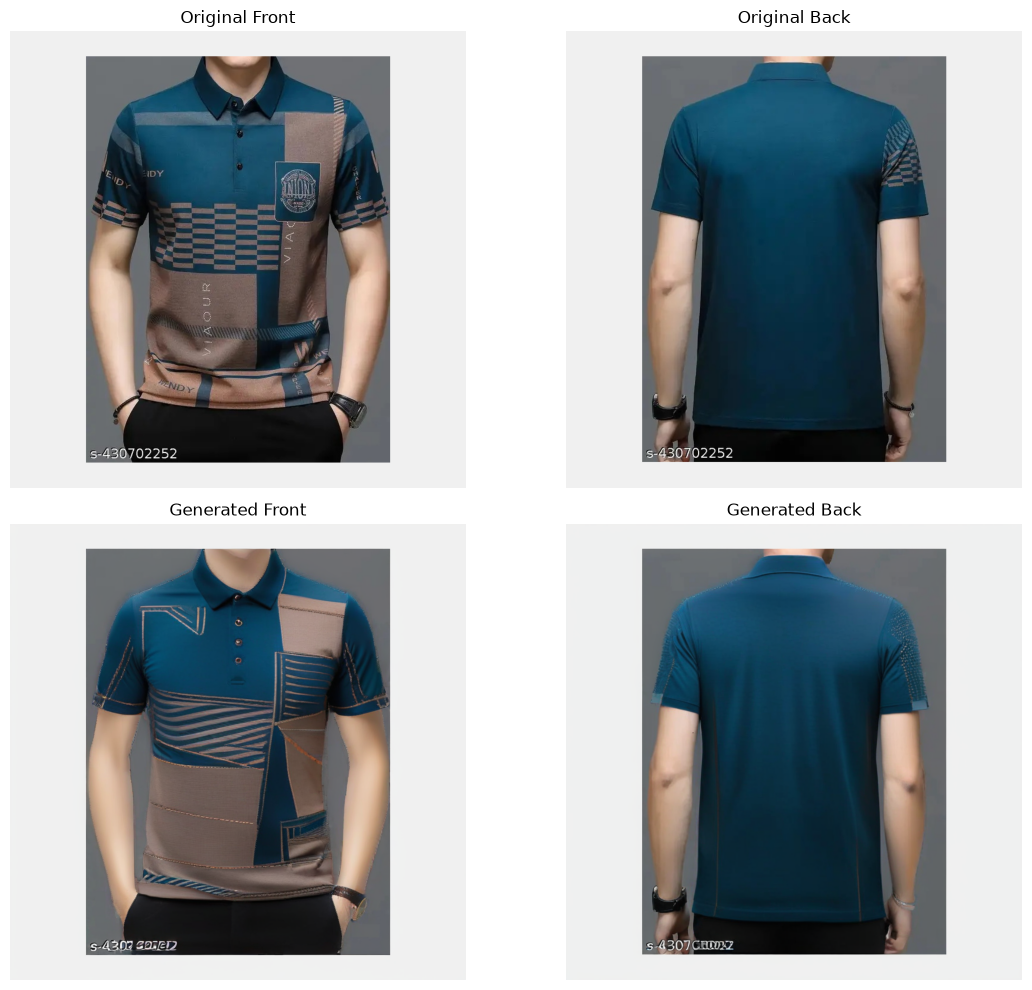

Output files:
generated_designs\P001\back_generated.png
generated_designs\P001\front_generated.png
generated_designs\P001\generation_report.csv


In [12]:

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for col, view in enumerate(["front", "back"]):
    axes[0, col].imshow(source_images[view])
    axes[0, col].set_title(f"Original {view.title()}")
    axes[0, col].axis("off")

    axes[1, col].imshow(generated_images[view])
    axes[1, col].set_title(f"Generated {view.title()}")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

print("Output files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path)
